# QDC 2026 challenge: Resolve prethermal Floquet structure

## Background - why this needs a quantum computer

A periodically driven ("**Floquet**") interacting spin system is kicked by the
*same* unitary over and over. Generic driven systems eventually **heat** to a
featureless infinite-temperature state, but before that there is a long-lived
**prethermal** window in which local observables keep a clean, structured
time-dependence. This challenge follows [Leviatan et al., *Resolving Structure in Prethermal
Floquet Dynamics with Precision Quantum Computation*](https://arxiv.org/abs/2607.24937). The signature we chase is a **subharmonic oscillation** of the
mean magnetization $M$: it repeats roughly every **4 drive periods**, not every
period.

Resolving that structure means reaching **many qubits** *and* **many drive
cycles at the same time** — the regime that stresses *both* classical and
quantum tools:

- **Classically**, exact statevector simulation is capped by memory at a few tens
  of qubits, and the approximate methods that go further (tensor networks, sparse
  Pauli-paths) lose control once entanglement and operator weight grow with cycle.
- **On raw hardware**, every extra cycle deepens the circuit, so noise piles up
  and the oscillation is buried after only a handful of cycles.

Making the signal *quantitatively trustworthy* deep into that regime is the whole
point: it is what turns the QPU from a demo into a measurement instrument. To do so, we drive the paper's 21-, 28-, 35- and 51-qubit heavy-hex patches for 30 cycles and ask: how long can error mitigation keep
the period-$\sim4$ magnetization oscillation trustworthy within 1,800 QPU seconds?


### The computation

The stroboscopic evolution operator for one **Floquet cycle** is a single unitary
$U_F$, applied cycle after cycle. It is **not** a small-step Trotterization of a
static Hamiltonian — the dynamics are *intrinsically* Floquet.

The key structural fact (paper Eq. 1) is that the drive is interleaved with the
interaction: the single-qubit $R_X(\theta_x)$/$R_Z(\theta_z)$ layer is re-applied
**before each of the three edge-coloured $R_{ZZ}(\theta_{zz})$ groups**, so one
cycle is **three sub-layers**:

$$U_F=\prod_{r=1}^{3}\Big[\Big(\textstyle\prod_{\langle i,j\rangle\in C_r}
        e^{-i\frac{\theta_{zz}}{2}Z_iZ_j}\Big)\,
        e^{-i\frac{\theta_z}{2}\sum_q Z_q}\,
        e^{-i\frac{\theta_x}{2}\sum_q X_q}\Big].$$

Because $R_X$ does **not** commute with $R_{ZZ}$, this cannot be collapsed into a
single $R_X$/$R_Z$ layer followed by all bonds — the two are genuinely different
unitaries. The three interleaved drives give an **effective per-cycle rotation
$3\theta_x=\pi/2$**, and that is exactly what produces the period-$\sim\!4$
subharmonic. (Collapsing it to one drive layer is the classic wrong answer, and
Exercise 1's grader rejects it.)

Three technical facts drive nearly every decision you will make:

- **Depth grows linearly with cycles.** The depth-$n$ experiment is $n$ stacked
  copies of $U_F$ — and each $U_F$ is itself three sub-layers. Depth is *the*
  resource, trading directly against accumulated noise and mitigation overhead.
- **It is hardware-native.** The heavy-hex bonds partition into three disjoint
  colour classes, so each $R_{ZZ}$ group is **one parallel layer** of native
  two-qubit gates — little routing, matched to Heron connectivity.
- **It is genuinely non-Clifford.** The fractional-angle $R_{ZZ}(\theta_{zz})$ is
  what makes the circuit classically hard and noise characterization non-trivial.

### The central trade-off, and how you're scored

Run the circuits **unmitigated** and you will *see the wall*: $M$ collapses toward
its noisy infinite-temperature value ($0$) within a few cycles (Exercise 3).
**Error mitigation** — readout correction, zero-noise extrapolation (gate folding
+ an extrapolation ansatz), gate/Pauli twirling, dynamical decoupling — buys back
trustworthy depth, but every one of these costs **QPU sampling time**.

That tension *is* the challenge. You have a hard **≤ 30-minute** Heron r3 budget
for the **entire** notebook (the `QPUBudget` helper tracks the running total), so
the real problem is: **push the mitigated, trusted depth as deep as possible per
QPU-second.**

**How you're scored.** The exercises below award 100 points for building and
extending the mitigation workflow, including the open-ended 74-qubit estimate of
Section 5.2. Hardware comparisons are print-only diagnostics that measure
agreement with the references, size by size:

- **21 / 28 / 35 qubits** — exact-statevector references (ground truth, computed for
  you, *not* part of the challenge). Compare how near the per-cycle ratio stays
  to $1.0$ and how many sampled cycles agree before it drifts.
- **51 qubits** — the error-mitigated experiment digitized from the paper's Fig. 3,
  the paper's headline size. Reproducing its response is the physical goal;
  the smaller sizes validate the workflow as you increase the system size.

Parts 4 and 5 overlay your runs on the references and report the per-cycle
**ratio to target**, centred on $1.0$, alongside MAE and sampled trusted depth.

### Structure of this notebook

In this notebook, you will do the following:

1. **Build** and **verify** the **Floquet circuit** (Part 1);
2. Observe the **noise wall** and apply a first mitigation pass (Part 2);
3. Improve the mitigation preparing **native compilation** with ```mapomatic``` and using **TREX** with the ```Executor``` (Part 3);
4. Further improve the mitigation using **custom extrapolations** for ZNE based on ```qiskit-mitigation``` (Part 4);
5. **Extend the workflow across sizes**, compare with available targets, possibly using Qiskit functions useful for these tasks (QESEM, Orbit, TEM) (Part 5).

The idea is **to build an iteratively-improved error mitigation scheme that eventually resolves the target physics**.

Cells marked **✏️ Your task** are exercises, **▶️ Run** cells are provided, and
**🔌 Hardware track** cells submit or retrieve QPU jobs only when both switches
are enabled. Every exercise ends with a `grade_lab_floquet_*` check cell that
evaluates your function on fixed inputs and submits no QPU jobs. Later cells use
your own functions, so fix a failing exercise before moving on. The hardware track has at most
**1,800 QPU seconds in total**; sampling only even cycles, the full track fits in less than **900 QPU seconds**.

Purple **🧪 Hint.** cells offer optional guidance: click the heading to reveal the hint text.

#### Tools you will use

| Tool | What it does | Code | Part |
|---|---|---|---|
| Qiskit circuits and compilation | Build $U_F$ and preserve native fractional $R_{ZZ}$ gates |  *yours*: `floquet_cycle`, `fold_cycles` | 1, 2, 3, 4 |
| Layout search | Place paper-coloured bonds on the backend | *imported*: `mapomatic`; *yours*: `choose_layout`, `select_mapomatic_layout` | 3, 5 |
| TREX and ZNE | Correct readout and extrapolate measured noise factors | *imported*: `client-side Estimator`, `qiskit_mitigation`; *yours*: `build_estimator`, `zne_linear_extrapolator` | 2, 3, 4, 5 |


In the Code column, *imported* are capabilities from the Qiskit ecosystem that you will use, whereas *yours* marks
a function written in an exercise. 

#### The goal, in one figure

Before the exercises, here is what a successful run looks like — the figure you
will reproduce and be scored on. The classical **reference** (exact statevector at
**21 / 28 / 35 qubits**, computed for you) and the **51-qubit** experiment
**digitized from the paper** are the ground truth; your Heron r3 trace gets
overlaid on top in Parts 4 and 5. The strip beneath each panel is the **target/hardware
ratio**, centred on $1.0$ — closer agreement over more cycles demonstrates
that the mitigation workflow carries to the larger patches.

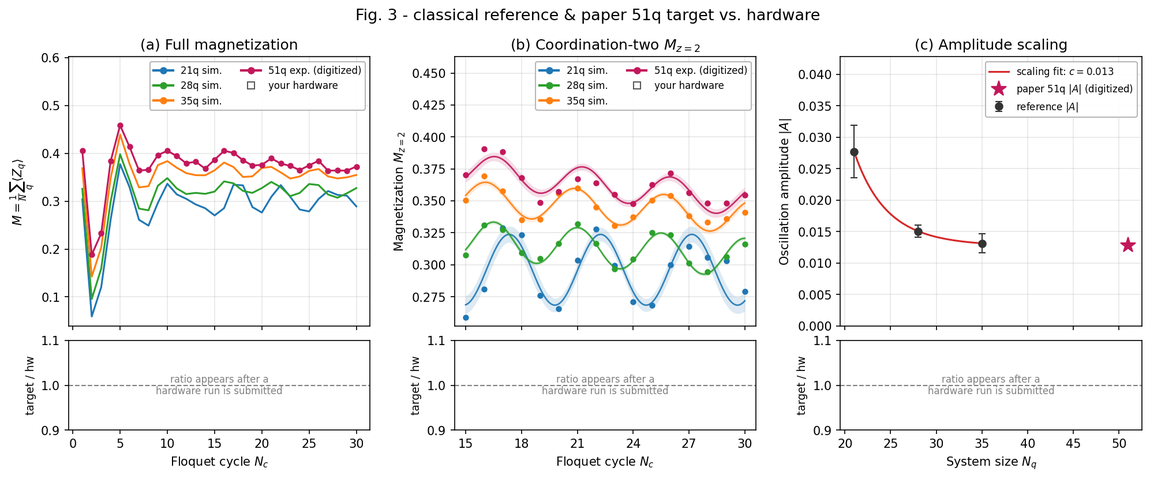

> **(a)** full magnetization $M$ vs. Floquet cycle · **(b)** coordination-two
> $M_{z=2}$ over cycles 15–30 with the Eq. 3 late-cycle fit · **(c)** the
> oscillation-amplitude finite-size scaling ($21\!\to\!28\!\to\!35$, extrapolating
> toward the 51q target). The empty ratio strips fill in once you submit a run;
> you build this figure live in Parts 2 and 4.


### Setup

Use Python 3.12 or later. From the `floquet-dynamics/` directory, create a
virtual environment and install the pinned requirements:

    python3 -m venv .venv && source .venv/bin/activate
    pip install -r requirements.txt

Start the Jupyter kernel in `floquet-dynamics/`, so that `utils/`, `reference/`
and `utils_qem/` can be imported. The hardware and Qiskit Serverless cells use
your saved IBM Quantum account (`QiskitRuntimeService.save_account(...)`).


<div class="alert alert-block alert-warning">

### Grading (100 points)

| Part | Graded exercises | Points |
|---|---|---:|
| 1 | lattice and colour groups 5 · `floquet_cycle` 5 | 10 |
| 2 | logical circuit and baseline magnetization 5 · first mitigation 10 | 15 |
| 3 | inverse `RZZ` 5 · layout 5 · Mapomatic 5 · TREX estimator 2.5 · observables 2.5 | 20 |
| 4 | cycle folding 5 · function to get expectation values 5 · ZNE fitter 5 · linear ZNE 2.5 · Richardson ZNE 2.5 · exponential ZNE 5 · model selection 5 | 30 |
| 5 | multi-size extension 15 · largest system sizes 10 | 25 |
| **Total** | | **100** |

Part 5's final 10 points belong to the open-ended 74-qubit estimate of Section 5.2.
The checks run through `qc-grader` and need an IBM Quantum account; run
`check_progress()` at the end to see your total. Hardware comparisons print the
accuracy (MAE) and sampled trusted depth of your measured traces. They are
diagnostics only and add nothing to the 100 points. Missing reference files
leave comparisons pending.

</div>


In [ ]:
import json
from pathlib import Path
import sys
import warnings
from functools import partial

ROOT = Path.cwd().resolve()
if not (ROOT / "utils" / "floquet_helpers.py").is_file():
    raise RuntimeError("Start the kernel in the floquet-dynamics/ directory.")
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
import rustworkx as rx
import mapomatic as mm
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Operator, SparsePauliOp
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime.fake_provider import FakeBoston

from utils import floquet_helpers as fh
from utils.floquet_helpers import FloquetParams, QPUBudget
from utils import plotting
from utils.runtime_helpers import (
    initialise_ledger, saved_run_settings, prepare_isa_circuits,
    run_program, charge_qpu_time, qpu_time_spent,
)
from reference import FloquetResult

try:  # readout correction in Part 2; raw counts are used without it
    import mthree
except ImportError:
    mthree = None

plotting.use_paper_style()

Grading goes through the challenge client, and QDC 2026 is played in teams: answers are only graded once you have joined your team. Set `TEAM_NAME` below and run the cell before you grade anything. Every member must type the team name exactly the same way (capitals and spaces count). It can have letters, digits, spaces, hyphens and underscores, up to 35 characters. Your team's best score on each exercise counts, so you can resubmit.

In [ ]:
from qc_grader.challenges.qdc_2026 import (
    check_progress, join_team,
    grade_lab_floquet_ex1_1, grade_lab_floquet_ex1_2,
    grade_lab_floquet_ex2_1, grade_lab_floquet_ex2_2,
    grade_lab_floquet_ex3_1, grade_lab_floquet_ex3_2a, grade_lab_floquet_ex3_2b,
    grade_lab_floquet_ex3_3a, grade_lab_floquet_ex3_3b,
    grade_lab_floquet_ex4_1, grade_lab_floquet_ex4_2, grade_lab_floquet_ex4_3a,
    grade_lab_floquet_ex4_3b, grade_lab_floquet_ex4_3c, grade_lab_floquet_ex4_3d,
    grade_lab_floquet_ex4_3e,
    grade_lab_floquet_ex5_1, grade_lab_floquet_ex5_2,
)

In [ ]:
TEAM_NAME = ""  # YOUR TEAM NAME, the same for every member

if TEAM_NAME:
    join_team(TEAM_NAME)
else:
    print("Set TEAM_NAME to your team's name and run this cell again: answers are only graded for a team.")

In [ ]:
# Connect to read backend data; RUN_QPU separately enables new submissions.
CONNECT_TO_QPU = True  # read live backend data and retrieve finished jobs
RUN_QPU = False        # submit NEW hardware jobs (costs QPU time)
BACKEND_NAME = "ibm_boston"  # the challenge backend

# Each run starts a fresh ledger (RESUME_JOBS=False) in a new runs/walkthrough_.../
# directory; older ledgers are kept. The ledger records job IDs, run settings and
# measured QPU charges (IBM stores the results). Save the printed path.
# To continue a run, set RESUME_JOBS=True and LEDGER_TO_RESUME to that path, using
# the original backend, shots, cycles and factors. Recorded jobs are retrieved and
# saved layouts restored; missing jobs are submitted only if RUN_QPU=True.
# Rerunning a measurement cell reuses the active ledger, so it never duplicates jobs.
# QPU_SPENT counts this ledger only. Reference traces load in either mode.
RESUME_JOBS = False
LEDGER_TO_RESUME = ROOT / "runs" / "walkthrough_jobs.json"
use_hardware = CONNECT_TO_QPU and (RUN_QPU or RESUME_JOBS)
LEDGER_PATH = (initialise_ledger(LEDGER_TO_RESUME, resume=RESUME_JOBS)
               if use_hardware else None)
if LEDGER_PATH is not None:
    print("Job ledger:", LEDGER_PATH)

if CONNECT_TO_QPU:
    from qiskit_ibm_runtime import QiskitRuntimeService
    service = QiskitRuntimeService()
    backend = service.backend(BACKEND_NAME, use_fractional_gates=True)
else:
    service, backend = None, FakeBoston()  # offline calibration snapshot; no native fractional RZZ
# Part 2 uses the standard gate target for Sampler and readout calibration.
backend_standard = (service.backend(BACKEND_NAME, use_fractional_gates=False)
                    if use_hardware else backend)
NQ = backend.num_qubits

QPU_SPENT = qpu_time_spent(LEDGER_PATH) if use_hardware else 0.0
print("track:", "hardware" if use_hardware else "local exercises", "| backend:", BACKEND_NAME)

## The fixed instance: floquet-colored-2026

The source reconstructs the paper's ordered, three-colour heavy-hex drive. The exact traces can be found in
the versioned `reference/traces_paper_colored_*q_v1.csv` files. Throughout the notebook, we will change compilation, measurement, and mitigation; but not the fixed drive angles or observable definitions.

| Item | Definition |
|---|---|
| Graph | Coloured heavy-hex patches at 21, 28, 35, and 51 qubits; three disjoint bond classes $C_1,C_2,C_3$ |
| Angles | $(\theta_x,\theta_z,\theta_{zz})=(\pi/6,\pi/27,\pi/3)$ |
| Initial state | $\lvert 0 \rangle^{\otimes N}$ |
| Observables | $M=\frac{1}{N_q}\sum_q\langle Z_q\rangle$, $M_{z=2}=\frac{1}{\lvert V_{z=2}\rvert}\sum_{q\in V_{z=2}}\langle Z_q\rangle$ |
| Grid | Cycles $n=0,2,4,\ldots,30$; known cycle zero; Part 2 factors $(1,3)$, Parts 4–5 factors $(1,3,5)$ |
| Inputs | Supplied corrected exact 21/28/35-qubit references and digitized 51-qubit paper trace. Any missing exact files are pending release inputs. |

**One Floquet cycle.** $U_F$ applies $R_X(\theta_x)$ and $R_Z(\theta_z)$ to every
qubit before *each* bond-colour layer $C_r$, then applies $R_{ZZ}(\theta_{zz})$
on that layer's disjoint bonds. The ordered interleaving matters because
$R_X$ and $R_{ZZ}$ do not commute; the three $X$ drives give an effective
$3\theta_x=\pi/2$ rotation per cycle.

**The target.** Estimate $M(n)$ and $M_{z=2}(n)$ through 30 cycles, preserving
the period-$\sim4$ subharmonic response. A corrected exact comparison is
loaded for every supplied exact size; the 51-qubit target is digitized from the paper.
Period and amplitude diagnostics use a damped-cosine fit on measured cycle
labels. Even sampling leaves frequency aliases and period-4 amplitude/phase
ambiguity; unidentifiable fits are reported as unavailable.

**Why three colours?** Each class has disjoint bonds, so its fractional-angle
$R_{ZZ}$ operations form one parallel two-qubit layer.

**Why a 30-minute cap?** Every extra cycle adds three drive-and-bond sub-layers,
and mitigation repeats circuits at multiple noise factors. The cap makes QPU
time part of the method choice.


In [ ]:
SPEC = fh.SPEC
INSTANCE_ID = fh.INSTANCE_ID
PARAMS = SPEC["params"]
N_CYCLES = SPEC["n_cycles"]
CYCLES = np.arange(2, N_CYCLES + 1, 2)
CYCLE_LABELS = np.r_[0, CYCLES]
SIZES = SPEC["sizes"]
SHOTS = 4096
FACTORS = SPEC["factors"]
PART2_FACTORS = (1, 3)
QPU_CAP_S = SPEC["qpu_cap_seconds"]
TOTAL_TARGET_S = 1800
JOB_ALLOWANCE_S = 1800
SHOTS_NEW = 4096
RANDOMIZATIONS = 32
TREX_CAL_RANDOMIZATIONS = 32 * 8
BASE_LATTICE = fh.paper_colored_lattice(21)
print(INSTANCE_ID, "|", BASE_LATTICE.n_qubits, "qubits,", BASE_LATTICE.n_edges,
      "couplers |", CYCLE_LABELS.tolist(), "cycle labels")

# Part 1: Build and verify the Floquet circuit (10 points)

### 1.1 Place the paper-coloured lattice

The paper's 21-qubit patch supplies the ordered bond classes. Within each
class the bonds are disjoint, so the $R_{ZZ}$ gates can run in parallel.

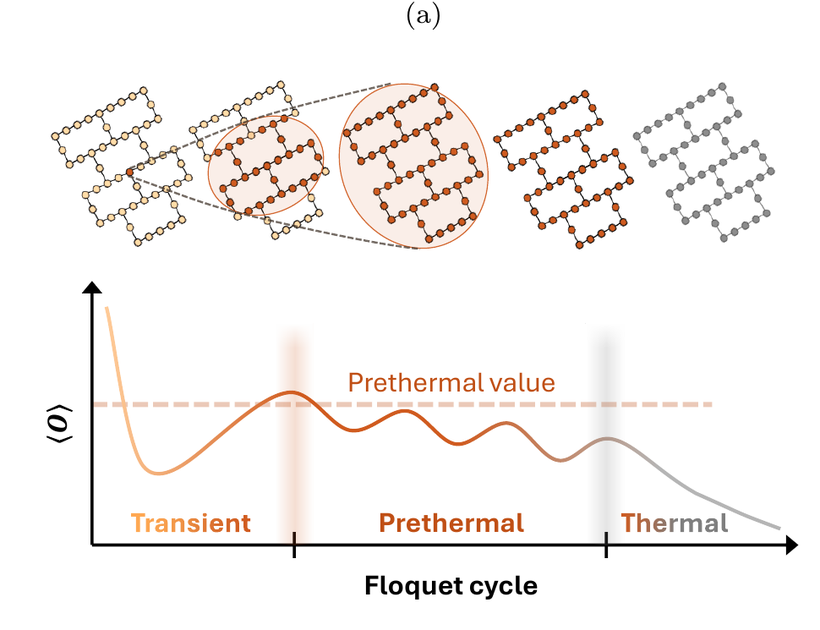


<div class="alert alert-block alert-success">

✏️ **Your task.** Set `lattice` to the corrected 21-qubit paper patch and `groups` to its three ordered colour classes (5 points).

</div>


In [ ]:
# TODO: Select the corrected 21-qubit paper patch.
lattice: object | None = None

# TODO: Obtain its three bond-colour groups in drive order.
groups: list[list[tuple[int, int]]] | None = None

<details class="alert alert-block" style="background-color: #f3e8ff; border: 1px solid #d8b4fe; border-left: 4px solid #9333ea; border-radius: 4px; color: #581c87; padding: 12px 16px;">
<summary style="cursor: pointer;">🧪 <strong>Hint.</strong></summary>
<p style="margin: 12px 0 0;">Inspect the helper functions in <code>floquet_helpers.py</code> (already imported as  <code>fh</code>) to find functions that may be useful.</p>
</details>

<div class="alert alert-block alert-info">

**Check the lattice and colour groups (5 points).** This check submits no jobs.

</div>


In [ ]:
grade_lab_floquet_ex1_1(lattice, groups)
print("qubits:", lattice.n_qubits, "| bonds:", lattice.n_edges,
      "| colour groups:", [len(group) for group in groups])

▶️ **Run the next cell.** Draw the corrected 21-qubit patch and its bond colouring:


In [ ]:
fh.plot_lattice(lattice);
plt.show()

### 1.2 Build one Floquet cycle

One cycle is three ordered sub-layers. In each, apply $R_X(\theta_x)$ and
$R_Z(\theta_z)$ on every qubit *before* that colour class's
$R_{ZZ}(\theta_{zz})$ bonds. A single drive layer followed by all bonds
implements a different unitary.

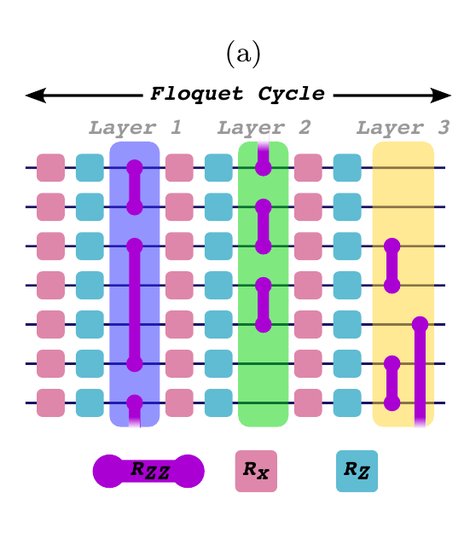


<div class="alert alert-block alert-success">

✏️ **Your task.** Write `floquet_cycle(qc, groups, params)` so it appends one ordered cycle to `qc` (5 points). The check compares the unitary on a small fixture.

</div>


In [ ]:
def floquet_cycle(qc: QuantumCircuit, groups: list[list[tuple[int, int]]],
                  params: FloquetParams) -> None:
    """Append one ordered three-colour Floquet cycle to ``qc`` in place.

    ``groups`` contains disjoint logical-qubit bonds in drive order; ``params``
    supplies the RX, RZ and RZZ angles. Each bond group is preceded by RX/RZ
    rotations on every qubit. This function returns None and adds no measurements.
    """
    # TODO: Visit the bond groups in drive order.
    # TODO: Apply the single-qubit drive before each group's interactions.
    # TODO: Append the group's two-qubit interactions.
    # This function has no output: it updates qc in place.
    pass



<div class="alert alert-block alert-info">

**Check `floquet_cycle` (5 points).** This check submits no jobs.

</div>


In [ ]:
grade_lab_floquet_ex1_2(floquet_cycle)

### 1.3 Compute the exact reference with Qiskit Serverless

The ground truth for $N=21$, $N=28$, and $N=35$ is an exact statevector evolution of $|0\cdots0\rangle$ under $U_F$, recording $M(n)$ and $M_{z2}(n)$ after every cycle. At $N=21$ the state holds $2^{21}$ amplitudes (32 MiB in double precision), but memory doubles with every qubit: at $N=35$ the same engine needs about 550 GiB in single precision. **Qiskit Serverless** runs Python functions on IBM's remote compute, so the organizers used it to compute all three exact references. You will run the $N=21$ case the same way.

Comparing against an exact classical reference is part of **validation**: one of the five rules for Universal Quantum Computation in the Presence of Errors. The other ones are: reporting the **run conditions** of the algorithm; defining a **trust boundary** that estimates the regime within the reported results remain connected to the target computation; **quantifying the uncertainty** of the computation through error bars and statistical analysis; and **cost transparency** when reporting the aggregated cost of a given computation. 

▶️ **Run the next cell.** Upload the exact statevector engine as a Qiskit Function, submit the $N=21$ reference for all 30 cycles, and wait for the result (a few seconds of compute plus queue time). The cell saves the job ID to `runs/serverless_ref21/job.json`, so rerunning it, even after a kernel restart, retrieves the same job instead of submitting a new one. It uses your saved IBM Quantum account and no QPU time:


In [ ]:
import shutil
import time

SL_FUNCTION = "floquet_paper_colored_reference"
SL_DIR = ROOT / "runs" / "serverless_ref21"
SL_JOB_FILE = SL_DIR / "job.json"
SL_NEW_JOB = False  # True: submit a fresh job even if one is recorded
SL_WAIT_S = 1800    # stop polling after this long; the job keeps running remotely

# Entrypoint run remotely: the pure-NumPy engine from reference/, at double precision.
ENGINE = '''\
from qiskit_serverless import get_arguments, save_result

from floquet_ref.lattice import paper_colored_lattice
from floquet_ref.simulator import FloquetParams, FloquetSimulator

args = get_arguments()
n_qubits, n_cycles = int(args["n_qubits"]), int(args["n_cycles"])
theta_x, theta_z, theta_zz = (float(a) for a in args["angles"])
sim = FloquetSimulator(paper_colored_lattice(n_qubits),
                       params=FloquetParams(theta_x=theta_x, theta_z=theta_z, theta_zz=theta_zz),
                       device="cpu", dtype="complex128")
res = sim.run(n_cycles, progress=True)
save_result({"n_qubits": int(res.n_qubits), "n_z2": int(res.n_z2),
             "cycles": [int(c) for c in res.cycles],
             "magnetization": [float(m) for m in res.magnetization],
             "magnetization_z2": [float(m) for m in res.magnetization_z2]})
'''


def stage_engine() -> Path:
    # Return a small upload folder: the entrypoint plus the three engine modules it imports.
    upload_dir = SL_DIR / "upload"
    pkg = upload_dir / "floquet_ref"
    shutil.rmtree(upload_dir, ignore_errors=True)
    pkg.mkdir(parents=True)
    for name in ("lattice.py", "simulator.py", "backend.py"):
        shutil.copy(ROOT / "reference" / name, pkg / name)
    (pkg / "__init__.py").write_text("")
    (upload_dir / "paper_colored_engine.py").write_text(ENGINE)
    return upload_dir


ref21 = None
try:
    from qiskit_ibm_catalog import QiskitServerless, QiskitFunction
    sl_client = QiskitServerless()
    if SL_JOB_FILE.is_file() and not SL_NEW_JOB:
        sl_job = sl_client.job(json.loads(SL_JOB_FILE.read_text())["job_id"])
        print("Retrieving recorded Serverless job:", sl_job.job_id)
    else:
        sl_function = sl_client.upload(QiskitFunction(title=SL_FUNCTION, entrypoint="paper_colored_engine.py",
                                                      working_dir=str(stage_engine())))
        sl_job = sl_function.run(n_qubits=21, n_cycles=int(N_CYCLES),
                                 angles=[PARAMS.theta_x, PARAMS.theta_z, PARAMS.theta_zz])
        SL_JOB_FILE.write_text(json.dumps({"job_id": sl_job.job_id, "function": SL_FUNCTION}))
        print("Submitted Serverless job:", sl_job.job_id, "| saved to", SL_JOB_FILE)

    t0, status = time.time(), None
    while not sl_job.in_terminal_state() and time.time() - t0 < SL_WAIT_S:
        if sl_job.status() != status:
            status = sl_job.status()
            print(f"  [{time.time() - t0:.0f} s] {status}")
        time.sleep(10)

    status = sl_job.status()
    if status == "DONE":
        out = sl_job.result()
        ref21 = FloquetResult(n_qubits=out["n_qubits"], cycles=np.asarray(out["cycles"]),
                              magnetization=np.asarray(out["magnetization"]),
                              magnetization_z2=np.asarray(out["magnetization_z2"]),
                              n_z2=out["n_z2"], params=PARAMS, device="serverless")
        print("exact reference:", ref21.n_qubits, "qubits,", len(ref21.cycles), "cycles",
              "| M(1) =", f"{ref21.magnetization[1]:.6f}", "| M_z2(1) =", f"{ref21.magnetization_z2[1]:.6f}")
    elif status in ("ERROR", "CANCELED"):
        print(f"Serverless job {status}; set SL_NEW_JOB = True to resubmit. Logs:\n{sl_job.logs()}")
    else:
        print(f"Still {status} after {SL_WAIT_S} s; rerun this cell to keep waiting.")
except Exception as exc:  # no account, no network, or a missing package
    print(f"Qiskit Serverless unavailable ({type(exc).__name__}: {exc})")
if ref21 is None:
    print("No Serverless result yet: use the hint below to load the supplied 21-qubit reference.")

<details class="alert alert-block" style="background-color: #f3e8ff; border: 1px solid #d8b4fe; border-left: 4px solid #9333ea; border-radius: 4px; color: #581c87; padding: 12px 16px;">
<summary style="cursor: pointer;">🧪 <strong>Hint.</strong></summary>
<p style="margin: 12px 0 0;">If Qiskit Serverless isn't available to you, or the job fails, load the organizers' copy of the same result instead. It is the supplied file <code>reference/traces_paper_colored_21q_v1.csv</code>:

<code>ref21 = fh.load_reference(21)</code>

<code>print("exact reference:", ref21.n_qubits, "qubits,", len(ref21.cycles), "cycles")</code>

</p>
</details>

The $N=28$ and $N=35$ references were also computed with Qiskit Serverless, using the same engine. For ease of implementation, the next cell loads them from the supplied files instead of recomputing them. The $N=51$ target is beyond exact simulation, so it is the paper's experimental trace, digitized from its Fig. 3.

▶️ **Run the next cell.** Load the 28-, 35-, and 51-qubit comparison targets.


In [ ]:
REFERENCE_PATHS = dict(fh.REFERENCE_PATHS)
REFERENCE_21_PATH = REFERENCE_PATHS[21]
if ref21 is None:
    raise RuntimeError("Compute ref21 with Serverless above, or load it with the hint, before continuing.")
paper_51q, amp51 = fh.load_paper_51q()
references_by_size = {21: ref21, 51: paper_51q}
for size in (28, 35):
    if REFERENCE_PATHS[size].is_file():
        references_by_size[size] = fh.load_reference(size, REFERENCE_PATHS[size])
    else:
        print(f"{size}q reference pending:", REFERENCE_PATHS[size])
print("exact 21q reference:", ref21.n_qubits, "qubits,", len(ref21.cycles), "cycles")

# Part 2: Observe the noise wall (15 points)

### 2.1 Extract the unmitigated baseline

The depth-$n$ circuit stacks $n$ copies of $U_F$ and measures every qubit.


<div class="alert alert-block alert-success">

✏️ **Your task.**

Implement these two functions (2.5 points each):

1. `logical_circuit(depth: int, lattice: object, groups: list[list[tuple[int, int]]],measured: bool = True) -> QuantumCircuit`: uses `floquet_cycle()` to output the quantum circuit stacking `depth` copies of a single Floquet step, and measures at the end.

1. `baseline_magnetizations(counts_list, lattice)`: return full $M$ and degree-two $M_{z=2}$ arrays, with cycle-0 value $1$ prepended to both.

</div>


In [ ]:
def logical_circuit(depth: int, lattice: object, groups: list[list[tuple[int, int]]],
                    measured: bool = True) -> QuantumCircuit:
    """Build ``depth`` Floquet cycles on the supplied logical lattice.

    ``groups`` gives its ordered colour classes. Use the currently accepted
    ``floquet_cycle`` and fixed ``PARAMS``; optionally append measurements from
    logical qubit q to classical bit q. Return a new circuit without compilation
    or hardware execution; ``measured=False`` provides unitary input for folding.
    """
    # TODO: Initialize a circuit on the logical lattice.
    # TODO: Stack the requested number of accepted Floquet cycles.
    # TODO: Add measurements when requested.
    # TODO: Return the new circuit.
    pass

def baseline_magnetizations(counts_list: list[dict[str, int]],
                            lattice: object) -> tuple[np.ndarray, np.ndarray]:
    """Convert ordered count dictionaries into raw ``(M, Mz2)`` traces.

    Use ``lattice`` to identify all sites and its degree-two subset. Counts use
    Qiskit's bitstring order, with qubit zero at the right. Return two float arrays
    in input order, each with the known fully polarized cycle-zero value 1 prepended.
    """
    # TODO: Extract both magnetizations from each count dictionary.
    # TODO: Prepend the fully polarized cycle-zero value to each trace.
    # TODO: Return the two arrays in input order.
    pass



<details class="alert alert-block" style="background-color: #f3e8ff; border: 1px solid #d8b4fe; border-left: 4px solid #9333ea; border-radius: 4px; color: #581c87; padding: 12px 16px;">
<summary style="cursor: pointer;">🧪 <strong>Hint.</strong></summary>
<p style="margin: 12px 0 0;">Inspect the helper functions in <code>floquet_helpers.py</code> (already imported as  <code>fh</code>) to find functions to compute the magnetization.</p>
</details>

▶️ **Run the next cell.** Import and configure the recoverable Sampler runner and readout-calibration tracker. They use the standard gate target selected during setup; importing them submits no jobs.

In [ ]:
# These helpers recover Sampler/calibration jobs and record their QPU usage.
from utils.execution_helpers import (
    run_counts as _run_counts,
    tracked_readout_calibration as _tracked_readout_calibration,
)

# Rerun this cell after changing execution settings or the selected lattice.
execution_options = {
    "use_hardware": use_hardware,
    "allow_submit": RUN_QPU,
    "backend_name": BACKEND_NAME,
    "service": service,
    "ledger_path": LEDGER_PATH,
}
run_counts = partial(
    _run_counts, backend=backend_standard, shots=SHOTS, **execution_options,
)
tracked_readout_calibration = partial(
    _tracked_readout_calibration, n_qubits=lattice.n_qubits, **execution_options,
)

<div class="alert alert-block alert-info">

**Check logical circuit and baseline magnetization (2.5 points each; 5 points total).** These checks submit no jobs.

</div>


In [ ]:
grade_lab_floquet_ex2_1(logical_circuit, baseline_magnetizations)

<div class="alert alert-block alert-warning">

🔌 **Hardware track.** Submit the 21-qubit unmitigated Sampler job at even cycles with 4,096 shots per circuit.

</div>


In [ ]:
m_unmit = mz2_unmit = None
if use_hardware:
    pm_baseline = generate_preset_pass_manager(optimization_level=3, backend=backend_standard,
                                               seed_transpiler=2026)
    depths = CYCLES.tolist()
    isa_baseline = prepare_isa_circuits(
        "baseline-21-standard",
        lambda: pm_baseline.run([logical_circuit(d, lattice, groups) for d in depths]),
        ledger_path=LEDGER_PATH,
    )
    counts, baseline_job_id, QPU_SPENT = run_counts(
        isa_baseline, "baseline-21", {"size": 21, "depths": depths, "mode": "raw"}
    )
    m_unmit, mz2_unmit = baseline_magnetizations(counts, lattice)
    baseline_metrics = fh.trace_diagnostics(m_unmit, ref21, label="Unmitigated",
                                            qpu_seconds=QPU_SPENT, cycles=CYCLE_LABELS)
else:
    print("Local track: enable hardware to measure the unmitigated baseline.")

### 2.2 Correct readout and extrapolate globally folded circuits

Now we implement a first pass of error mitigation. In particular, we will use:

- `mthree` readout correction to correct measurement errors when sampling. `mthree` calibrates a simplified error model (neglecting high-order correlations between measured qubits) and uses it to invert the noisy measurement channel after sampling. Calibrate the physical qubits used by the transpiled measurement circuits, then apply the correction in each circuit's measurement order.

- Logical-circuit folds at noise factors $1,3$ (`PART2_FACTORS`). Folding preserves the ideal unitary while increasing gate noise; append measurements and transpile afterward. Fit $$M(\lambda)=a\lambda+b$$ cycle by cycle and extract the mitigated results as $$M_{\rm ZNE}=b\,.$$


<div class="alert alert-block alert-success">

✏️ **Your task.** Implement these four functions (2.5 points each; 10 points total):

1. `make_readout_mitigator(isa_list, *, use_hardware, backend, calibration_tracker, mthree_module)`: create an `mthree_module.M3Mitigation(backend)` and calibrate the union of the circuits' physical qubits with `cals_from_system()`. Use the `calibration_tracker(mitigator, qubits)` context manager (the run cell passes `tracked_readout_calibration`) for calibration settings and job accounting. Return `None` on the local track (`use_hardware=False`) or if `mthree_module` is `None`.
2. `corrected_mags(counts_list, isa_list, lattice, mitigator=None)`: optionally apply readout correction with each circuit's physical-qubit layout, then return full $M$ and degree-two $M_{z=2}$ arrays on `lattice`. Accept bitstring or integer quasi-probability keys and retain signed weights.
3. `folded_isa(depth, scale, lattice, groups)`: globally fold an unmeasured logical depth-$n$ circuit, then append measurements. The run cell handles transpilation.
4. `zne_extrapolate(per_scale, scales=FACTORS)`: return the scale-zero linear intercept at each measured cycle.

Keep both observables in the same cycle order. Prepend cycle zero only in the final run cell. Defining these functions submits no jobs; the tracking helper was imported in Section 2.1.

</div>


In [ ]:
def make_readout_mitigator(
    isa_list: list[QuantumCircuit],
    *,
    use_hardware: bool,
    backend,
    calibration_tracker,
    mthree_module,
) -> "mthree.M3Mitigation | None":
    """Create and calibrate mthree on the ISA circuits' physical qubits.

    ``isa_list`` contains transpiled measured circuits with layouts. Create
    ``mthree_module.M3Mitigation(backend)`` and calibrate the sorted union of their
    physical qubits inside ``calibration_tracker(mitigator, qubits)``, which yields
    the calibration settings and handles recovery and QPU charging. Return the
    mitigator, or None when ``use_hardware`` is False or ``mthree_module`` is None.
    Calling this function can submit a calibration job; calibration failures propagate.
    """
    # TODO: Handle the local track and the optional mthree dependency.
    # TODO: Collect the physical qubits used by the measured circuits.
    # TODO: Create and calibrate the mitigator with the provided tracker.
    # TODO: Return the calibrated mitigator, or None when unavailable.
    pass


def corrected_mags(
    counts_list: list[dict[str | int, float]],
    isa_list: list[QuantumCircuit],
    lattice: object,
    mitigator: "mthree.M3Mitigation | None" = None,
) -> tuple[np.ndarray, np.ndarray]:
    """Extract ``(M, Mz2)`` from matched counts and measured ISA circuits.

    Optionally apply ``mitigator`` in each circuit's physical measurement order;
    a circuit without a layout uses logical order. Accept integer or bitstring keys
    and preserve signed quasi-probability weights. ``lattice`` defines the observable
    sites. Return two float arrays in circuit order, without prepending cycle zero.
    """
    # TODO: Match each count dictionary to its circuit's measurement order.
    # TODO: Apply readout correction when a mitigator is supplied.
    # TODO: Handle both key formats while preserving signed weights.
    # TODO: Return both magnetization arrays without adding cycle zero.
    pass


def folded_isa(depth: int, scale: int, lattice: object,
               groups: list[list[tuple[int, int]]]) -> QuantumCircuit:
    """Globally fold the logical depth circuit and append measurements.

    Use the accepted ``logical_circuit`` with ``lattice`` and its colour ``groups``.
    ``scale`` is a positive odd factor, e.g. 1, 3 or 5. Folding the unmeasured circuit
    preserves its ideal unitary while scaling the gate count. Return a measured logical
    circuit; the run cell performs transpilation despite this function's legacy name.
    """
    # TODO: Build the unmeasured logical depth circuit.
    # TODO: Apply global folding at the requested scale.
    # TODO: Append measurements and return the circuit.
    pass


def zne_extrapolate(per_scale: dict[int, np.ndarray],
                    scales: tuple[int, ...] = FACTORS) -> np.ndarray:
    """Return cycle-wise linear zero-noise intercepts for ``per_scale``.

    Each selected entry maps a noise scale to the same ordered measured-cycle trace.
    Fit a line using at least two distinct ``scales`` and evaluate it at scale zero.
    Return one float per input cycle, without prepending cycle zero. Missing scales
    or incompatible trace lengths are reported by indexing or NumPy fitting.
    """
    # TODO: Gather the selected noise-scale values for each measured cycle.
    # TODO: Fit the linear model and extract its zero-noise intercept.
    # TODO: Return the intercept array in cycle order.
    pass



<div class="alert alert-block alert-info">

**Check first mitigation (2.5 points per function; 10 points total).** The check runs your functions with a mock calibration module, synthetic counts and a small folding fixture. It submits no jobs.

</div>


In [ ]:
grade_lab_floquet_ex2_2(make_readout_mitigator, corrected_mags, folded_isa, zne_extrapolate)

<div class="alert alert-block alert-warning">

🔌 **Hardware track.** Build and transpile globally folded circuits at factors $1,3$ and even cycles, calibrate their physical-qubit readout, sample each factor with 4,096 shots, correct both observables, then extrapolate to zero noise and compare the trace with the reference (a diagnostic, not graded). Each job is saved by ID and charged once. If `mthree` is missing, use raw counts; hardware calibration/accounting failures remain visible. The local track performs no calibration or Sampler run.

</div>


In [ ]:
m_mit = mz2_mit = first_pass_metrics = None
if use_hardware:
    depths = CYCLES.tolist()
    pm_first_pass = generate_preset_pass_manager(optimization_level=3, backend=backend_standard,
                                                 seed_transpiler=2026)
    isa_by_scale = {
        scale: prepare_isa_circuits(
            f"first-pass-21-scale-{scale}-standard",
            lambda scale=scale: pm_first_pass.run(
                [folded_isa(depth, scale, lattice, groups) for depth in depths]
            ),
            ledger_path=LEDGER_PATH,
        )
        for scale in PART2_FACTORS
    }
    all_isa = [circuit for scale in PART2_FACTORS for circuit in isa_by_scale[scale]]
    mitigator = make_readout_mitigator(
        all_isa, use_hardware=use_hardware, backend=backend_standard,
        calibration_tracker=tracked_readout_calibration, mthree_module=mthree,
    )
    QPU_SPENT = qpu_time_spent(LEDGER_PATH)
    print("readout mitigation:",
          "ENABLED" if mitigator is not None else "DISABLED (raw counts)")

    per_scale_M, per_scale_Mz2, first_pass_job_ids = {}, {}, {}
    for scale in PART2_FACTORS:
        counts_s, job_id, QPU_SPENT = run_counts(
            isa_by_scale[scale], f"first-pass-21-scale-{scale}",
            {"size": lattice.n_qubits, "depths": depths, "scale": scale,
             "mode": "global-fold-mthree" if mitigator is not None else "global-fold-raw"},
        )
        first_pass_job_ids[scale] = job_id
        per_scale_M[scale], per_scale_Mz2[scale] = corrected_mags(
            counts_s, isa_by_scale[scale], lattice, mitigator,
        )

    m_mit = np.r_[1.0, zne_extrapolate(per_scale_M, PART2_FACTORS)]
    mz2_mit = np.r_[1.0, zne_extrapolate(per_scale_Mz2, PART2_FACTORS)]
    first_pass_metrics = fh.trace_diagnostics(m_mit, ref21, label="First-pass mitigated",
                                              qpu_seconds=QPU_SPENT, cycles=CYCLE_LABELS)
else:
    print("Local track: first-pass mthree hardware results are not loaded.")

▶️ **Run the next cell.** Compare the first-pass mitigated full magnetization `m_mit` with the exact classical 21-qubit reference. Both traces include cycle zero.


In [ ]:
# Compare the first mitigation pass with the exact reference, including cycle zero.
from utils.plotting import plot_mitigated_magnetization

if m_mit is not None:
    plot_mitigated_magnetization(
        m_mit, reference=ref21, measured_cycles=CYCLE_LABELS,
    );
    plt.show()
else:
    print("No m_mit results available; run the first mitigation pass before plotting.")

As the figure above demonstrates, these results, although error-mitigated, are not accurate enough. To solve it, in Parts 3 and 4 we will improve the whole pipeline before extending the calculation to bigger system sizes. 


# Part 3: Prepare native compilation and readout (20 points)

As a first step to get better results, we will improve the circuit compilation and use more sophisticated readout-mitigation techniques. In particular:

- In 3.1, we will implement the entangling operations using fractional gates. As we will check, this significantly reduces circuit depth.
- In 3.2, we will choose a circuit layout that minimizes the two-qubit gate and readout errors. 
- In 3.3, we will implement TREX to mitigate readout errors.


### 3.1 Implement the entangling gates using the native $R_{ZZ}$ fractional gates

The Heron fractional-gate target supports a positive-angle native
$R_{ZZ}(\theta_{zz})$. Since this is precisely the type of entangling gates used in the circuit, enabling them in the backend definition will significantly reduce circuit depth.

However, fractional gates add an additional complication. To implement gate folding, we need to implement an $R_{ZZ}$ gate with a negative angle. Since this is not supported by the Heron devices, we will instead conjugate by $X$ on one qubit. This gives the inverse while keeping the native $R_{ZZ}$, so we will use that to implement the gate inverses. Note that barriers protect that construction during compilation.


In [ ]:
if CONNECT_TO_QPU:
    backend = service.backend(BACKEND_NAME, use_fractional_gates=True)

<div class="alert alert-block alert-success">

✏️ **Your task.** Write `normalize_inverse_rzz(qc)` so negative-angle $R_{ZZ}$ operations become equivalent positive-angle native operations without changing the unitary (5 points).

</div>


In [ ]:
def normalize_inverse_rzz(qc: QuantumCircuit) -> QuantumCircuit:
    """Return an equivalent circuit whose negative RZZ angles are positive.

    For each negative RZZ, conjugate its positive-angle counterpart by X on one
    endpoint. Preserve other operations and the circuit's registers; barriers protect
    the conjugation during compilation. Do not mutate ``qc``. The fixed drive later
    allows the native-ISA audit to verify every RZZ against ``PARAMS.theta_zz``.
    """
    # TODO: Create an empty copy preserving the circuit's registers.
    # TODO: Replace negative RZZ operations with protected native equivalents.
    # TODO: Preserve all other operations and return the new circuit.
    pass



<div class="alert alert-block alert-info">

**Check `normalize_inverse_rzz` (5 points).** This check submits no jobs.

</div>


In [ ]:
grade_lab_floquet_ex3_1(normalize_inverse_rzz)

▶️ **Run the next cell.** Import the provided no-routing pass manager, native-ISA audit, and compiler. The compiler uses the inverse-RZZ normalization accepted above.


In [ ]:
# Compile without routing and reject unsupported RZZ gates or extra entanglers.
from utils.floquet_compilation import (
    make_pm,
    check_isa as _check_isa,
    compile_native as _compile_native,
)

# Bind the normalization accepted by the preceding exercise check.
# Rerun this cell after changing that implementation or the drive parameters.
check_isa = partial(_check_isa, theta_zz=PARAMS.theta_zz)
compile_native = partial(
    _compile_native, normalize=normalize_inverse_rzz, theta_zz=PARAMS.theta_zz,
)

### 3.2 Choose a low-error physical placement

Use the calibrated $R_{ZZ}$ edges and readout errors to compare graph
embeddings. The source also uses Mapomatic to rank layouts of the deepest
30-cycle circuit. On the local track, deterministic fixtures check the
functions; physical layouts are selected on the hardware track.


<div class="alert alert-block alert-success">

✏️ **Your task.** Write `choose_layout` to find a SWAP-free paper-patch embedding and minimize the source's bond-error plus readout-error cost over up to `limit` candidates (5 points).

</div>


In [ ]:
def choose_layout(backend: object, lattice: object, groups: list[list[tuple[int, int]]],
                  limit: int = 10, missing_error: float = 0.01) -> list[int]:
    """Find a low-error, SWAP-free logical-to-physical lattice embedding.

    ``backend`` must expose native fractional RZZ edges. ``lattice`` and ``groups``
    define the logical graph. Score at most ``limit`` VF2 candidates by summed bond
    error plus summed readout error divided by 30; use ``missing_error`` where calibration
    error is absent. Print the search summary and return physical qubits in logical
    site order. Raise when the target or a compatible embedding is unavailable.
    """
    # TODO: Validate the fractional-RZZ target and identify its native edges.
    # TODO: Build the device graph and the logical bond graph.

    def error(gate: str, qargs: tuple[int, ...]) -> float:
        """Read a calibrated gate error, allowing reversed two-qubit edges.

        ``gate`` is rzz or measure; ``qargs`` gives physical qubits. Return the target's
        error probability, or the enclosing ``missing_error`` when calibration is absent.
        """
        # TODO: Look up calibration, allowing reversed bonds and missing errors.
        # TODO: Return the error probability.
        pass

    # TODO: Search up to limit compatible embeddings and score their layouts.
    # TODO: Report the search and return the lowest-cost layout, or raise if absent.
    pass



<details class="alert alert-block" style="background-color: #f3e8ff; border: 1px solid #d8b4fe; border-left: 4px solid #9333ea; border-radius: 4px; color: #581c87; padding: 12px 16px;">
<summary style="cursor: pointer;">🧪 <strong>Hint.</strong></summary>
<p style="margin: 12px 0 0;">Use <code>rx.vf2_mapping(device, logical, subgraph=True, induced=False, id_order=False)</code> to search for embeddings. Each mapping relates physical qubits to logical sites; invert it to build the logical-to-physical layout, then compare candidates using the bond-error and readout-error cost.</p>
</details>


<div class="alert alert-block alert-info">

**Check `choose_layout` (5 points).** This check submits no jobs.

</div>


In [ ]:
grade_lab_floquet_ex3_2a(choose_layout)

<div class="alert alert-block alert-success">

✏️ **Your task.** Write `select_mapomatic_layout(qc, backend)` to translate the deepest measured circuit, rank compatible layouts with Mapomatic, and return `(layout, estimated_error)` (5 points).

</div>


In [ ]:
def select_mapomatic_layout(qc: QuantumCircuit, backend: object) -> tuple[list[int], float]:
    """Rank compatible physical layouts for the supplied measured circuit.

    Translate ``qc`` into RZ/SX/X/RZZ operations, find compatible Mapomatic layouts
    on ``backend``, and evaluate their calibration-based errors. Return the lowest
    ``(layout, estimated_error)``, with physical qubits in logical order. Raise
    ValueError when no compatible layout is found. This function submits no jobs.
    """
    # TODO: Translate the measured circuit to the native gate basis.
    # TODO: Find and score compatible layouts with Mapomatic.
    # TODO: Return the best layout and error, or raise when none are compatible.
    pass



<div class="alert alert-block alert-info">

**Check the Mapomatic layout (5 points).** This check submits no jobs.

</div>


In [ ]:
grade_lab_floquet_ex3_2b(select_mapomatic_layout)

<div class="alert alert-block alert-warning">

🔌 **Hardware track.** Read the live fractional-gate target and select a 21-qubit layout without submitting a QPU job.

</div>


In [ ]:
backend_frac = backend if use_hardware else None
run21 = None
if use_hardware:
    previous = saved_run_settings("trex-21q", backend_name=BACKEND_NAME, ledger_path=LEDGER_PATH)
    if previous is not None:
        layout21 = list(previous["layout"])
        print("resumed layout:", layout21)
    else:
        deepest = logical_circuit(N_CYCLES, lattice, groups)
        mapomatic_candidate, mapomatic_error = select_mapomatic_layout(deepest, backend_frac)
        custom_candidate = choose_layout(backend_frac, lattice, groups)
        translated = transpile(deepest, basis_gates=["rz", "sx", "x", "rzz"], optimization_level=0)
        custom_scores = mm.evaluate_layouts(translated, [custom_candidate], backend_frac)
        custom_error = float(custom_scores[0][1]) if custom_scores else float("inf")
        layout21 = custom_candidate if custom_error < mapomatic_error else mapomatic_candidate
        print("live layout:", layout21, "| estimated error:", f"{min(custom_error, mapomatic_error):.4f}")
    pm_frac21 = make_pm(layout21, backend_frac)
else:
    layout21 = pm_frac21 = None
    print("Local track: layout selection and measurement require hardware.")

▶️ **Run the next cell.** Plot the gate and readout errors across the entire device and the selected optimal layout. These metrics are part of the **run conditions**, whose reporting constitute one of the five rules for Universal Quantum Computation in the Presence of Errors discussed above.

In [ ]:
if backend_frac is not None and layout21 is not None:
    plotting.plot_floquet_layouts(backend_frac, layout21, groups)
    plotting.plot_floquet_error_cdfs(backend_frac, layout21, groups)
    plt.show()
else:
    print("Local track: the device error maps need a live backend with fractional gates.")

▶️ **Run the next cell.** Compute the total number of 2Q gates and the 2Q-gate depth of the different circuits, also part of the run conditions.

In [ ]:
# Count two-qubit gates to compare compilation and entangling-gate overhead.
from utils.floquet_compilation import two_qubit_gate_counts

if backend_frac is not None and layout21 is not None:
    isa_check = compile_native(
        logical_circuit(N_CYCLES, lattice, groups),
        backend_frac, layout21, pm_frac21,
    )
    expected_rzz = N_CYCLES * lattice.n_edges
    check_isa(isa_check, expected_rzz, backend_frac, layout21)

    # Compare the same cycle count and noise factor (1).
    circuits = [
        ("2.1 Baseline", isa_baseline[-1]),
        ("2.2 First mitigation, factor 1", isa_by_scale[1][-1]),
        ("3.2 Native RZZ + selected layout", isa_check),
    ]

    print(f"{lattice.n_qubits} qubits | {N_CYCLES} cycles | noise factor 1")
    print(f"{'Compilation':<36} {'Depth':>8} {'2q gates':>10}  Gate breakdown")
    for label, circuit in circuits:
        counts_2q = two_qubit_gate_counts(circuit)
        print(
            f"{label:<36} {circuit.depth():>8} "
            f"{sum(counts_2q.values()):>10}  {counts_2q}"
        )

    native_2q = sum(two_qubit_gate_counts(isa_check).values())
    for label, circuit in circuits[:-1]:
        previous_2q = sum(two_qubit_gate_counts(circuit).values())
        if previous_2q:
            reduction = 100 * (previous_2q - native_2q) / previous_2q
            print(f"2q gate reduction versus {label}: {reduction:.1f}%")
else:
    print("Compilation comparison requires a fractional-RZZ backend and selected layout.")

### 3.3 Configure TREX and the observables

The source switches to the Runtime Estimator for TREX readout mitigation.
It uses 4,096 shots, 32 measurement-twirling randomizations, 256
measurement-noise-learning randomizations, gate twirling off, and dynamical
decoupling off. The Estimator returns expectation values, so define $M$ and
$M_{z=2}$ as sparse Pauli operators.


<div class="alert alert-block alert-success">

✏️ **Your task.** Write `build_estimator(backend, allowance)` with the source's TREX, twirling, and shot settings, and a job time limit of `allowance` seconds (2.5 points).

</div>


In [ ]:
from qiskit_ibm_runtime.executor_estimator import Estimator

def build_estimator(backend: object, allowance: int = JOB_ALLOWANCE_S) -> Estimator:
    """Construct the TREX Estimator for a native fractional-RZZ backend.

    ``allowance`` limits a job's execution time in seconds. Use the notebook's shot,
    measurement-twirling and calibration-randomization settings; enable TREX, disable
    server-side ZNE, gate twirling and dynamical decoupling. Return the configured
    Estimator without submitting a job. Raise for a missing or incompatible backend.
    """
    # TODO: Validate the backend and construct its Estimator.
    # TODO: Set the job allowance, shots, and readout-mitigation options.
    # TODO: Configure noise learning, twirling, and decoupling as specified.
    # TODO: Return the configured Estimator without submitting a job.
    pass

<div class="alert alert-block alert-info">

**Check `build_estimator` (2.5 points).** This check submits no jobs.

</div>


In [ ]:
grade_lab_floquet_ex3_3a(
    build_estimator, shots=SHOTS_NEW, randomizations=RANDOMIZATIONS,
    cal_randomizations=TREX_CAL_RANDOMIZATIONS,
)

<div class="alert alert-block alert-success">

✏️ **Your task.** Write `make_observables(lattice)` to return sparse operators for $M$ over all qubits and $M_{z=2}$ over degree-two qubits, in that order (2.5 points).

</div>


In [ ]:
def make_observables(lattice: object) -> list[SparsePauliOp]:
    """Return sparse Pauli operators ``[M, Mz2]`` on the logical lattice.

    Average single-site Z over all ``lattice.n_qubits`` sites for M and over sites of
    degree two for Mz2. The order is the measurement runner's observable order. Raise
    ValueError when there are no degree-two sites. The runner maps these operators
    to physical qubits after compilation.
    """
    # TODO: Identify all sites and the degree-two subset.
    # TODO: Build each normalized sparse Z observable; reject an empty subset.
    # TODO: Return the operators in the runner's observable order.
    pass



<div class="alert alert-block alert-info">

**Check `make_observables` (2.5 points).** This check submits no jobs.

</div>


In [ ]:
grade_lab_floquet_ex3_3b(make_observables)

# Part 4: Fold cycles and choose a ZNE model (30 points)

After Part 3 optimization of the compilation, layout, and measurement procedure, now we can apply mitigation in the observable measurements again.

### 4.1 Scale noise one Floquet cycle at a time

Global folding of each *cycle* preserves its ideal unitary and multiplies its
fractional-angle $R_{ZZ}$ count by the odd factor. This differs from folding
the full depth-$n$ circuit once. The task checks both the unitary and the gate
count on a small fixture before any hardware job is allowed.


<div class="alert alert-block alert-success">

✏️ **Your task.** Write `fold_cycles(depth, lattice, groups, factor)` to stack `depth` copies of a globally folded *one-cycle* circuit (5 points). Use factors $1,3,5$.

</div>


In [ ]:
def fold_cycles(depth: int, lattice: object, groups: list[list[tuple[int, int]]],
                factor: int) -> QuantumCircuit:
    """Stack ``depth`` copies of a globally folded single Floquet cycle.

    Build one unmeasured cycle with the accepted ``logical_circuit`` and supplied
    lattice/colour groups. ``factor`` is a positive odd noise factor, e.g. 1, 3 or 5.
    Return a new unmeasured logical circuit with the same ideal evolution as ``depth``
    unfolded cycles and a factor-scaled RZZ count. Compilation is performed later.
    """
    # TODO: Build and globally fold one unmeasured Floquet cycle.
    # TODO: Stack depth copies of the folded cycle in a new circuit.
    # TODO: Return the unmeasured circuit.
    pass

<div class="alert alert-block alert-info">

**Check `fold_cycles` (5 points).** This check submits no jobs.

</div>


In [ ]:
grade_lab_floquet_ex4_1(fold_cycles)

▶️ **Run the next cell.** Verify the unitary and expected $R_{ZZ}$ count on the source's small fixture:


In [ ]:
small_lattice = fh._test_lattice()
small_groups = fh.color_groups(small_lattice)
for depth in (1, 2):
    ideal = Operator(logical_circuit(depth, small_lattice, small_groups, measured=False))
    for factor in FACTORS:
        folded = fold_cycles(depth, small_lattice, small_groups, factor)
        assert Operator(folded).equiv(ideal)
        assert Operator(normalize_inverse_rzz(folded)).equiv(ideal)
        assert folded.count_ops().get("rzz", 0) == factor * depth * small_lattice.n_edges
print("cycle-fold checks: factors", FACTORS, "| depths 1, 2 | unitary and RZZ count passed")

### 4.2 Acquire folded TREX expectation values

Measure $M$ and $M_{z=2}$ at every chosen cycle and factor with the configured
Estimator. Save each new job ID in this execution's ledger before waiting for
results. Rerunning the cell retrieves that job; starting with a fresh ledger
submits a new experiment. The local track runs exercises without loading
organizer measurements.


<div class="alert alert-block alert-success">

✏️ **Your task.** Write `measure_cycle_folded(lattice, groups, backend, layout, cycles, factors, *, use_hardware, service, build_estimator, run_program, charge_qpu_time)` to prepare the job sent to the QPU (5 points). This function defines the cycle-folded Estimator runner for the target lattice and groups, selecting the optimal layout already found, and has to support fractional backends. The execution helpers are parameters, so the check can call your function with fakes; the cell after the check binds the real ones once with `functools.partial`.

</div>

In [ ]:
def measure_cycle_folded(lattice: object, groups: list[list[tuple[int, int]]],
                         backend: object, layout: list[int], cycles,
                         factors: tuple[int, ...], *, use_hardware: bool, service: object,
                         build_estimator, run_program, charge_qpu_time) -> dict:
    """Run or recover the cycle-folded TREX experiment and charge its QPU use.

    ``lattice``/``groups`` define the logical drive, ``backend`` is its fractional-RZZ
    target, and ``layout`` lists physical qubits in logical order. Measure every
    requested ``cycles``/``factors`` pair using the accepted folding, observable,
    Estimator and compilation functions. PUBs are ordered cycle first, then factor;
    map both observables through each ISA layout before execution.

    Build the Estimator with ``build_estimator(backend)``. Submit through
    ``run_program`` (``service.job`` retrieves recorded jobs) and record the charge
    with ``charge_qpu_time``, using the active ledger and shot settings. Record a
    new job ID before waiting, or retrieve a matching recorded job. Return a run dict
    with cycles, factors, PUB order, job/provenance metadata and ``values``/``stds``
    arrays of shape (cycles, factors) for M and Mz2. No cycle-zero row is added.
    ``qpu_seconds`` is this job's measured charge; the ledger tracks the cumulative
    total. Raise for empty inputs, disabled hardware, result-shape problems or missing
    charge metrics. Calling this function may submit a QPU job.
    """
    cycles = np.asarray(list(cycles), dtype=int)
    factors = tuple(int(factor) for factor in factors)
    if len(cycles) == 0 or not factors:
        raise ValueError("Provide at least one cycle and one noise factor")
    if not use_hardware:
        raise RuntimeError("Estimator jobs require both hardware switches.")

    observables = # we have created a function to do this
    pm = # we have imported a function to do this (make_pm)
    pub_order = [(int(cycle), factor) for cycle in cycles for factor in factors]
    pubs = []
    for cycle, factor in pub_order:
        # use fold_cycles and compile_native to create a pubs list

    estimate = QPUBudget.estimate(len(pubs), shots=SHOTS_NEW)
    estimator = # we have created a function to do this
    key = f"trex-{lattice.n_qubits}q"
    settings = {
        "size": lattice.n_qubits, "cycles": cycles.tolist(), "factors": list(factors),
        "shots": SHOTS_NEW, "randomizations": RANDOMIZATIONS,
        "trex_cal_randomizations": TREX_CAL_RANDOMIZATIONS, "layout": list(layout),
    }
    job = # we have imported a function to do this: run_program
    result = job.result()
    if len(result) != len(pub_order):
        raise RuntimeError("Estimator returned the wrong number of PUB results")

    shape = (len(cycles), len(factors), len(observables))
    evs = np.stack([np.asarray(item.data.evs, dtype=float).reshape(-1)
                    for item in result]).reshape(shape)
    stds = np.stack([np.asarray(item.data.stds, dtype=float).reshape(-1)
                     for item in result]).reshape(shape)
    try:
        charged = float(job.metrics()["usage"]["qpu_charge_time_seconds"])
    except (AttributeError, KeyError, TypeError, ValueError) as exc:
        raise RuntimeError("Inspect job metrics and record its QPU charge before another submit") from exc
    job_id = job.job_id() if callable(job.job_id) else job.job_id
    total = charge_qpu_time(key, job_id=job_id, qpu_seconds=charged, ledger_path=LEDGER_PATH)
    print(f"{lattice.n_qubits}q: {len(pubs)} PUBs | job {job_id} | total QPU {total:.1f} s")
    return {
        "n_qubits": lattice.n_qubits, "cycles": cycles, "factors": factors,
        "pub_order": pub_order,
        "values": {"M": evs[:, :, 0], "Mz2": evs[:, :, 1]},
        "stds": {"M": stds[:, :, 0], "Mz2": stds[:, :, 1]},
        "job_id": job_id, "job": job, "qpu_seconds": charged,
        "backend": BACKEND_NAME, "layout": list(layout), "provenance": "user",
    }

<div class="alert alert-block alert-info">

**Check `measure_cycle_folded` (5 points).** The check calls your function with a fake backend, Estimator, job runner and ledger, so it submits no jobs and charges no QPU time.

</div>


In [ ]:
grade_lab_floquet_ex4_2(measure_cycle_folded)

▶️ **Run the next cell.** Bind the real execution helpers once. Parts 4 and 5 call `measure` with the same arguments as before.


In [ ]:
measure = partial(
    measure_cycle_folded, use_hardware=use_hardware, service=service,
    build_estimator=build_estimator, run_program=run_program,
    charge_qpu_time=charge_qpu_time,
)

<div class="alert alert-block alert-warning">

🔌 **Hardware track.** Measure 21 qubits at factors $1,3,5$ with TREX on the selected backend, or retrieve the job from the active ledger. Production uses `ibm_boston`; testing uses `ibm_aachen`. The local track skips measurement.

</div>


In [ ]:
if use_hardware:
    run21 = measure(lattice, groups, backend_frac, layout21, cycles=CYCLES, factors=FACTORS)
    QPU_SPENT = qpu_time_spent(LEDGER_PATH)
    print("21q factors:", run21["factors"], "| measured PUBs:", len(run21["pub_order"]))
else:
    print("Local track: no quantum measurements loaded; exercises use synthetic check fixtures.")

▶️ **Run the next cell.** Plot your expectation values at each measured noise factor:


In [ ]:
if run21 is not None:
    plotting.plot_cycle_folded(run21);
    plt.show()

### 4.3 Compare zero-noise extrapolators

The source uses `qiskit-mitigation` for linear, Richardson-polynomial, and
bounded exponential fits. For each cycle, extrapolate the measured values to
noise factor zero. Benchmark against the corrected 21-qubit exact $M$ trace;
the chosen model is later applied to both observables at every size.


<div class="alert alert-block alert-success">

✏️ **Your task.** Write `_qmit_zne` as a Qiskit Mitigation fitter. It validates factor columns, uses their standard errors, and returns one zero-noise estimate per measured cycle (5 points).

</div>


In [ ]:
from collections.abc import Callable, Mapping, Sequence
from typing import Any
from utils.floquet_zne import _zne_data

def _qmit_zne(
    run: Mapping[str, Any],
    chosen_factors: Sequence[int],
    observable: str,
    model: str,
    custom_fit_factory: Callable[[np.ndarray, np.ndarray], Any] | None = None,
) -> np.ndarray:
    """Fit each measured cycle with Qiskit Mitigation and evaluate at zero noise.

    Args:
        run: Measurement dictionary containing ``cycles``, ``factors``, ``values``
            and ``stds``. Observable arrays have shape ``(cycles, factors)``.
        chosen_factors: At least two distinct measured noise factors, in the order
            supplied to the fit.
        observable: Key of the magnetization and standard-error arrays to fit.
        model: Qiskit Mitigation model name selected by the participant exercise.
        custom_fit_factory: Optional per-cycle callback accepting factor and value
            arrays. It returns ``(fit_function, initial_parameters, bounds)`` for
            the custom model, where the function accepts factor coordinates
            followed by fit parameters. The notebook defines these constraints.

    Returns:
        One zero-noise value per measured cycle, preserving the run's row order.

    Raises:
        ValueError: Measured inputs fail ``_zne_data`` validation.
        RuntimeError: Fits return non-finite values; the message identifies the
            corresponding physical cycle labels.

    The upstream ``_fit_extrapolation_models`` function is a private API used by
    the challenge's pinned Qiskit Mitigation version. Keeping its import here
    isolates that version dependency. Standard errors are passed to the fitter
    unchanged; this helper neither performs measurements nor modifies the run.
    """
    # TODO: Validate and select the factor columns with _zne_data.
    # TODO: Prepare an optional custom fit for each measured cycle.
    # TODO: Fit using the cycle's standard errors and evaluate at zero noise.
    # TODO: Report non-finite fits with their physical cycle labels.
    # TODO: Return the estimates in measured-cycle order.
    pass

<div class="alert alert-block alert-info">

**Check the ZNE fitter (5 points).** The check verifies factor selection, standard errors, custom fits, and failure reporting. It submits no jobs.

</div>


In [ ]:
grade_lab_floquet_ex4_3a(_qmit_zne)

<div class="alert alert-block alert-success">

✏️ **Your task.** Write `zne_linear_extrapolator` for the zero-noise linear model. Return one value per measured cycle, in source order (2.5 points).

</div>


In [ ]:
def zne_linear_extrapolator(run21: dict, chosen_factors: tuple[int, ...] = (1, 3, 5),
                            observable: str = "M") -> np.ndarray:
    """Fit linear ZNE and return one estimate per measured cycle.

    ``run21`` supplies ordered cycles, factor columns and observable values/errors.
    Select ``chosen_factors`` for ``observable`` (M or Mz2), then use the common fitter
    to evaluate the fitted line at zero noise. Preserve cycle order without adding
    cycle zero; invalid inputs or failed fits are reported by the provided fitter.
    """
    # TODO: Use the common fitter with the linear model and return its estimates.
    pass



<div class="alert alert-block alert-info">

**Check linear ZNE (2.5 points).** This check submits no jobs.

</div>


In [ ]:
grade_lab_floquet_ex4_3b(zne_linear_extrapolator)

<div class="alert alert-block alert-success">

✏️ **Your task.** Write `zne_richardson_extrapolator` using a polynomial of degree one less than the number of chosen factors (2.5 points).

</div>


In [ ]:
def zne_richardson_extrapolator(run21: dict, chosen_factors: tuple[int, ...] = (1, 3, 5),
                                observable: str = "M") -> np.ndarray:
    """Fit Richardson-polynomial ZNE in the run's measured-cycle order.

    Select ``chosen_factors`` for ``observable`` from the run's values and standard
    errors. Use polynomial degree ``len(chosen_factors) - 1`` and evaluate at zero
    noise, returning one value per cycle without adding cycle zero. Raise above the
    supported degree seven; the common fitter validates factors and reports failures.
    """
    # TODO: Determine the polynomial degree and check its supported range.
    # TODO: Use the common fitter with that polynomial and return its estimates.
    pass



<div class="alert alert-block alert-info">

**Check Richardson ZNE (2.5 points).** This check submits no jobs.

</div>


In [ ]:
grade_lab_floquet_ex4_3c(zne_richardson_extrapolator)

<div class="alert alert-block alert-success">

✏️ **Your task.** Write `zne_exponential_extrapolator` with bounded nonnegative decay rate and a signed amplitude (5 points).

</div>


In [ ]:
def zne_exponential_extrapolator(run21: dict, chosen_factors: tuple[int, ...] = (1, 3, 5),
                                observable: str = "M",
                                rate_bounds: tuple[float, float] = (0.0, 2.0)) -> np.ndarray:
    """Fit signed-amplitude exponential ZNE with a bounded decay rate.

    Use selected factor columns and standard errors for ``observable`` in ``run21``.
    ``rate_bounds`` must be finite and satisfy 0 <= lower < upper; allow either sign
    for amplitude so negative magnetizations remain representable. Return zero-noise
    amplitudes in measured-cycle order without cycle zero. Invalid bounds raise
    ValueError; the common fitter reports input and fit failures.
    """
    # TODO: Validate the decay-rate bounds.

    def exponential(factor: np.ndarray, amplitude: float,
                    rate: float) -> np.ndarray:
        """Return signed-amplitude exponential values at the noise factors.

        ``factor`` contains noise coordinates; ``amplitude`` is the zero-noise
        value and ``rate`` is the decay rate. Return an array matching ``factor``.
        """
        # TODO: Evaluate the exponential model.
        pass

    def fit_spec(
        factors: np.ndarray, observed: np.ndarray,
    ) -> tuple[Callable[..., np.ndarray], list[float], tuple[list[float], list[float]]]:
        """Return the fit model, initial parameters and bounds for one cycle.

        ``factors`` and ``observed`` are matching noise-coordinate and measured-value
        arrays. Seed the rate inside the enclosing bounds and infer signed amplitude
        from the largest-magnitude observation. Return the model callable, initial
        parameter list and lower/upper bounds; amplitude remains unbounded.
        """
        # TODO: Choose signed initial parameters and the fit bounds.
        # TODO: Return the custom-fit specification.
        pass

    # TODO: Use the common fitter with the custom model and return its estimates.
    pass



<div class="alert alert-block alert-info">

**Check exponential ZNE (5 points).** This check submits no jobs.

</div>


In [ ]:
grade_lab_floquet_ex4_3d(zne_exponential_extrapolator)

▶️ **Run the next cell.** Plot the source's three candidate extrapolations against the corrected 21-qubit trace:


In [ ]:
if run21 is not None:
    candidate_values = [
        zne_linear_extrapolator(run21, chosen_factors=(1, 3)),
        zne_richardson_extrapolator(run21, chosen_factors=(1, 3, 5)),
        zne_exponential_extrapolator(run21, chosen_factors=(1, 3)),
    ]
    plotting.plot_zne_extrapolation(ref21.magnetization, candidate_values,
                                    ["Linear", "Richardson", "Exponential"],
                                    reference_cycles=ref21.cycles,
                                    measured_cycles=np.r_[0, run21["cycles"]]);
    plt.show()

<div class="alert alert-block alert-success">

✏️ **Your task.** Write `select_zne_model(run21, reference_trace)` to compare factors $(1,3)$ and $(1,3,5)$ for all three models, then return the factor tuple and method name with the lowest source RMSE at measured cycles through 30 (5 points).

</div>


In [ ]:
def select_zne_model(run21: dict, reference_trace: np.ndarray) -> tuple[tuple[int, ...], str]:
    """Choose the factor tuple and ZNE model closest to the exact M reference.

    Align ``reference_trace`` with ``run21``'s measured cycle labels. Compare the
    accepted linear, Richardson and exponential implementations at factors (1, 3)
    and (1, 3, 5). Return ``(factors, method_name)`` for the lowest root-sum-square
    error; this gives the same ranking as RMSE on this common cycle grid. Preserve
    candidate order to break ties. Reference-alignment and fit failures propagate.
    """
    # TODO: Align the exact reference with the measured cycle labels.
    # TODO: Compare each model and factor tuple on the same reference grid.
    # TODO: Return the best factor tuple and method name, preserving tie order.
    pass



<div class="alert alert-block alert-info">

**Check ZNE model selection (5 points).** This check submits no jobs.

</div>


In [ ]:
grade_lab_floquet_ex4_3e(select_zne_model)
selected_factors, selected_method = FACTORS, "linear"
if run21 is not None:
    best_method = select_zne_model(run21, ref21.magnetization)
    selected_factors, selected_method = best_method
    print("selected factors:", selected_factors, "| ZNE method:", selected_method)
else:
    print("Measure the 21q experiment before selecting a ZNE model.")

# Part 5: Extend and compare system sizes (25 points)

### 5.1 Carry the selected workflow to 28, 35, and 51 qubits

Carry the selected 21-qubit TREX/ZNE workflow to the paper-coloured 28, 35,
and 51-qubit patches, keeping the drive, cycle grid, and noise factors fixed.
The runner measures every requested cycle-factor pair for both observables.
`FloquetResult` preserves the measured cycle labels and both magnetizations.
Supplied references are loaded automatically; missing files leave comparisons
pending. Section 5.1 awards 15 points; the open-ended 74-qubit estimate of Section 5.2 awards 10.


▶️ **Run the next cell.** Import the Mapomatic helper for larger layouts. It ranks embeddings of the deepest circuit and retains only native-RZZ-compatible patches; this cell submits no jobs.


In [ ]:
# Find larger-patch layouts whose bonds use calibrated native RZZ edges.
from utils.floquet_compilation import mapomatic_layout as _mapomatic_layout

# Rerun this cell after changing the logical circuit builder or cycle count.
mapomatic_layout = partial(
    _mapomatic_layout, logical_circuit=logical_circuit, n_cycles=N_CYCLES,
)

<div class="alert alert-block alert-success">

✏️ **Your task — Extend the mitigation workflow across system sizes (15 points).**

Write `extend_sizes` to carry the accepted 21-qubit workflow to **28, 35, and
51 qubits**. Reuse the provided helpers so the drive, observables, mitigation
settings, job recovery, and budget accounting follow the earlier parts.

1. Build each paper-coloured patch and its ordered colour groups. Retain the
   existing 21-qubit lattice and any available baseline run (5 points).
2. Reuse the layout saved for an existing experiment, or select a
   native-RZZ-compatible layout with `mapomatic_layout` (5 points).
3. When `use_hardware` is enabled, run or retrieve the larger-size measurements
   using the supplied `cycles` and `selected_factors`. Store each run and layout
   by size, and read cumulative QPU usage from the shared ledger. The local
   track builds the patches without calling execution or ledger helpers (5 points).

Return a dictionary with `lattices_by_size`, `groups_by_size`, `runs_by_size`,
`layout_by_size`, and `qpu_seconds`. The check supplies fake hardware helpers;
defining the function and running its check submits no jobs.

</div>


In [ ]:
def extend_sizes(
    lattice: object,
    run21: dict[str, Any] | None,
    *,
    cycles: Sequence[int] | np.ndarray,
    selected_factors: tuple[int, ...],
    use_hardware: bool,
    backend: object | None,
    backend_name: str,
    ledger_path: Path | None,
    saved_run_settings: Callable[..., dict[str, Any] | None],
    mapomatic_layout: Callable[..., list[int]],
    measure_cycle_folded: Callable[..., dict[str, Any]],
    qpu_time_spent: Callable[[Path], float],
) -> dict[str, Any]:
    """Apply the selected measurement workflow to all three larger paper patches.

    ``lattice`` and optional ``run21`` preserve the 21-qubit baseline. ``cycles`` and
    ``selected_factors`` define the larger-size measurement plan. ``use_hardware``
    guards calls using ``backend``, ``backend_name`` and ``ledger_path``.

    The supplied callbacks look up saved run settings, choose layouts, run or recover
    measurements, and read cumulative QPU time. Local execution constructs patches
    and preserves the optional baseline without calling hardware or ledger helpers.
    Hardware execution recovers saved layouts before acquiring each experiment.
    Return a dictionary with ``lattices_by_size``, ``groups_by_size``, ``runs_by_size``,
    ``layout_by_size`` and ``qpu_seconds``. Execution and budget failures propagate.
    """
    # TODO: Build the larger patches and their ordered colour groups.
    # TODO: Retain the 21-qubit lattice and any existing run and layout.
    # TODO: On the hardware track, reuse saved layouts or choose new ones.
    # TODO: Run or retrieve each larger patch with the selected measurement plan.
    # TODO: Return the size-keyed artifacts and cumulative QPU usage.
    pass

<details class="alert alert-block" style="background-color: #f3e8ff; border: 1px solid #d8b4fe; border-left: 4px solid #9333ea; border-radius: 4px; color: #581c87; padding: 12px 16px;">
<summary style="cursor: pointer;">🧪 <strong>Hint.</strong></summary>
<p style="margin: 12px 0 0;">Use <code>fh.paper_colored_lattice(size)</code> and
<code>fh.color_groups(lat)</code> for each patch. Use its saved layout when
available; otherwise call <code>mapomatic_layout</code> with that patch and backend.</p>
<p><code>measure_cycle_folded</code> already handles folding, both observables,
compilation, job submission or recovery, and QPU charging. Pass it the patch,
its groups and layout, and the selected measurement plan. Store its returned run
under the system size, then use <code>qpu_time_spent(ledger_path)</code> for the
cumulative time. Keep all execution and ledger calls behind the hardware guard.</p>
</details>

<div class="alert alert-block alert-info">

**Check multi-size extension (15 points).** The check awards 5 points each
for patches, layout selection, and guarded acquisition/accounting. It calls
your function with fake callbacks, so it submits no jobs.

</div>


In [ ]:
grade_lab_floquet_ex5_1(extend_sizes, lattice)

<div class="alert alert-block alert-warning">

🔌 **Hardware track.** Apply the accepted multi-size workflow on the configured
backend, or retrieve jobs from the active ledger. The local track builds the
patches and skips larger-size measurements.

</div>


In [ ]:
multi_size_run = extend_sizes(
    lattice, run21, cycles=CYCLES, selected_factors=selected_factors,
    use_hardware=use_hardware, backend=backend_frac, backend_name=BACKEND_NAME,
    ledger_path=LEDGER_PATH, saved_run_settings=saved_run_settings,
    mapomatic_layout=mapomatic_layout, measure_cycle_folded=measure,
    qpu_time_spent=qpu_time_spent,
)
lattices_by_size = multi_size_run["lattices_by_size"]
groups_by_size = multi_size_run["groups_by_size"]
runs_by_size = multi_size_run["runs_by_size"]
layout_by_size = multi_size_run["layout_by_size"]
QPU_SPENT = multi_size_run["qpu_seconds"]

▶️ **Run the next cell.** Apply each extrapolator, keep the selected result, and build source-compatible `FloquetResult` objects:


In [ ]:
extrapolators = {
    "linear": zne_linear_extrapolator,
    "richardson": zne_richardson_extrapolator,
    "exp": zne_exponential_extrapolator,
}
extrapolated_by_size = {}
hardware_results_by_size = {}

for size, run_for_size in runs_by_size.items():
    extrapolated_by_size[size] = {
        name: {
            observable: extrapolator(run_for_size, chosen_factors=selected_factors,
                                      observable=observable)
            for observable in ("M", "Mz2")
        }
        for name, extrapolator in extrapolators.items()
    }
    selected = extrapolated_by_size[size][selected_method]
    hardware_results_by_size[size] = FloquetResult(
        n_qubits=size,
        cycles=np.r_[0, run_for_size["cycles"]],
        magnetization=np.r_[1.0, selected["M"]],
        magnetization_z2=np.r_[1.0, selected["Mz2"]],
        n_z2=sum(degree == 2 for degree in lattices_by_size[size].degrees()),
        params=PARAMS,
        device=run_for_size["backend"],
    )

hardware_results = [hardware_results_by_size[size] for size in sorted(hardware_results_by_size)]
print("selected ZNE:", selected_method, selected_factors,
      "| sizes:", [result.n_qubits for result in hardware_results])

▶️ **Run the next cell.** Compare TREX and all three ZNE models against the supplied references:


In [ ]:
if runs_by_size:
    plotting.plot_multi_size_zne(runs_by_size, extrapolated_by_size,
                                 selected_method, ref21, paper_51q, n_cycles=N_CYCLES,
                                 references_by_size=references_by_size);
    plt.show()

▶️ **Run the next cell.** Overlay the selected traces on the paper-style Fig. 3 panels:


In [ ]:
fh.figure3_comparison_partial(
    [reference for size, reference in references_by_size.items() if size != 51],
    hardware_results=hardware_results,
    paper_51q=paper_51q, paper_51q_amplitude=amp51,
)
plt.show()

▶️ **Run the next cell.** Print hardware diagnostics (MAE and trusted depth) for your selected traces. They add nothing to the 100-point total. Sizes without supplied targets remain pending.


In [ ]:
hardware_report = fh.hardware_diagnostics(hardware_results_by_size, references_by_size,
                                           QPU_SPENT)
print(f"Target: {QPU_SPENT:.1f}/{TOTAL_TARGET_S} QPU seconds | "
      + ("MET" if QPU_SPENT <= TOTAL_TARGET_S else "EXCEEDED")
      if use_hardware else "Total target: no hardware usage measured.")

### 5.2 Targeting the paper's largest system sizes

<div class="alert alert-block alert-success">

✏️ **Your task — Pushing the system sizes as much as possible.**

Use your remaining QPU time to compute $M_{z=2}(n=18)$ for the biggest lattice in the paper, $N=74$. You will score by the closeness to the actual value reported there, $M_{z=2}(n=18)\sim 0.356\pm 0.005$.

Report it with a one-standard-deviation (68 %) statistical error bar; any method is allowed.
An estimate within 0.02 of 0.356 earns 10 points, and one within 0.05 earns 5. The error
bar $\sigma$ must satisfy $0<\sigma\le 0.05$ and
$|M_{z=2}-0.356|\le 3\sqrt{\sigma^2+0.005^2}$, otherwise the estimate earns no points.
The result is self-reported: the grader sees only the two numbers you submit.

Reporting the error bars is part of the **uncertainty quantification**: another of the five rules for Universal Quantum Computation in the Presence of Errors.

</div>


In [ ]:
# TODO: Set both from your own N=74 run, obtained by any method.
MZ2_74: float | None = None        # your estimate of M_z2(n=18) on the 74-qubit patch
MZ2_74_ERROR: float | None = None  # its one-standard-deviation statistical error bar

<div class="alert alert-block alert-info">

**Check your 74-qubit estimate (10 points).** The grader sees only the two numbers you submit, so this result is self-reported. This check submits no jobs.

</div>


In [ ]:
grade_lab_floquet_ex5_2(MZ2_74, MZ2_74_ERROR)

▶️ **Run the next cell.** See which exercises you have passed and your total score:


In [ ]:
check_progress()

## References

1. E. Leviatan, T. Watad, R. Perry *et al.*, [*Resolving Structure in Prethermal Floquet Dynamics with Precision Quantum Computation*](https://arxiv.org/abs/2607.24937), arXiv:2607.24937 (2026).
2. Supplied corrected paper-coloured exact traces and digitized 51-qubit target: see `reference/README.md`.
3. [Qiskit documentation](https://qiskit.org/documentation/), [IBM Quantum Runtime documentation](https://quantum.cloud.ibm.com/docs/), and [Mapomatic repository](https://github.com/Qiskit-Community/mapomatic).

© IBM Corp. 2026
